In [19]:

import numpy as np
from scipy.integrate import solve_ivp

def sir_model(t, y, beta, gamma, N):
    S, I, R = y

    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I

    return [dSdt, dIdt, dRdt]

# Model parameters
N = 1000
beta = 0.30
gamma = 0.10

# Initial conditions
initial_state = [990, 10, 0]

solution = solve_ivp(
    sir_model,
    t_span=(0, 100),
    y0=initial_state,
    args=(beta, gamma, N),
    method="RK45",
    t_eval=np.linspace(0, 100, 1001)
)


In [20]:
print("Simulation successful:", solution.success)
print("Time points:", solution.t)
print("SIR values:", solution.y)

Simulation successful: True
Time points: [  0.    0.1   0.2 ...  99.8  99.9 100. ]
SIR values: [[9.90000000e+02 9.89700101e+02 9.89394332e+02 ... 5.86335317e+01
  5.86307968e+01 5.86280829e+01]
 [1.00000000e+01 1.01989075e+01 1.04016770e+01 ... 1.56261756e+00
  1.54980288e+00 1.53708665e+00]
 [0.00000000e+00 1.00991349e-01 2.03991065e-01 ... 9.39803851e+02
  9.39819400e+02 9.39834830e+02]]


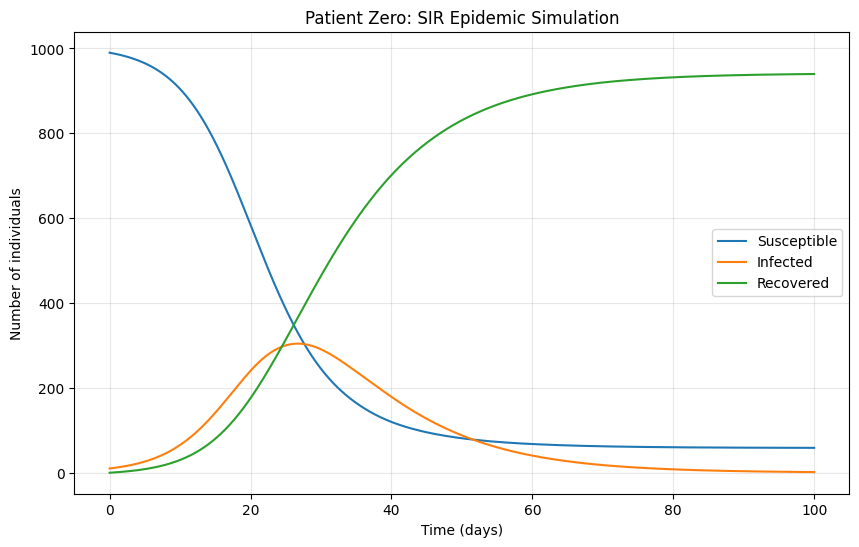

In [21]:
import matplotlib.pyplot as plt

# Extract results
time = solution.t
S, I, R = solution.y

# Create visualization
plt.figure(figsize=(10, 6))

plt.plot(time, S, label="Susceptible")
plt.plot(time, I, label="Infected")
plt.plot(time, R, label="Recovered")

plt.xlabel("Time (days)")
plt.ylabel("Number of individuals")
plt.title("Patient Zero: SIR Epidemic Simulation")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [22]:
peak_index = np.argmax(I)

print("Peak infections:", round(I[peak_index], 2))
print("Peak day:", time[peak_index])
print("Total population at final time:", round(S[-1] + I[-1] + R[-1], 2))
print("Function evaluations:", solution.nfev)

Peak infections: 304.29
Peak day: 26.700000000000003
Total population at final time: 1000.0
Function evaluations: 92


In [23]:
# Theoretical susceptible threshold for the infection peak
S_threshold = gamma * N / beta

# Susceptible population at the sampled peak
S_at_peak = S[peak_index]

print(f"Theoretical threshold: {S_threshold:.2f}")
print(f"Susceptible at sampled peak: {S_at_peak:.2f}")

Theoretical threshold: 333.33
Susceptible at sampled peak: 330.35


In [24]:
# Check population conservation across all time points
total_population = S + I + R

max_conservation_error = np.max(
    np.abs(total_population - N)
)

# Check whether any compartment becomes negative
minimum_compartment = np.min(solution.y)

print(f"Maximum conservation error: {max_conservation_error:.10f}")
print(f"Minimum compartment value: {minimum_compartment:.10f}")

assert np.allclose(total_population, N, atol=1e-6)
assert np.all(solution.y >= -1e-8)

print("Validation checks passed!")

Maximum conservation error: 0.0000000000
Minimum compartment value: 0.0000000000
Validation checks passed!


In [25]:
def euler_sir(beta, gamma, N, initial_state, days, dt):
    steps = int(days / dt)

    time_euler = np.linspace(0, days, steps + 1)
    states = np.zeros((3, steps + 1))

    states[:, 0] = initial_state

    for step in range(steps):
        t = time_euler[step]
        current_state = states[:, step]

        # Calculate derivatives using our existing SIR function
        derivatives = np.array(
            sir_model(t, current_state, beta, gamma, N)
        )

        # Euler update: new = old + rate * time step
        states[:, step + 1] = current_state + derivatives * dt

    return time_euler, states

In [26]:
t_euler_1, y_euler_1 = euler_sir(
    beta, gamma, N, initial_state, 100, 1.0
)

t_euler_01, y_euler_01 = euler_sir(
    beta, gamma, N, initial_state, 100, 0.1
)

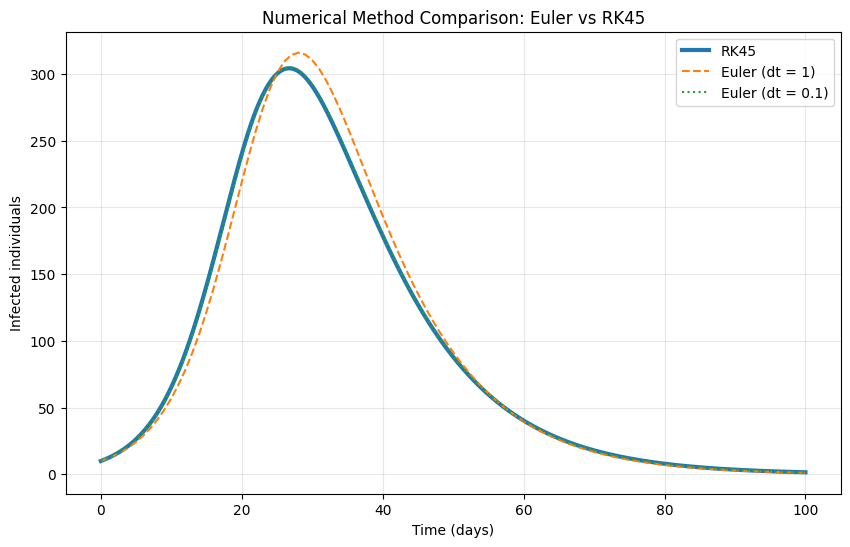

In [27]:
plt.figure(figsize=(10, 6))

plt.plot(
    solution.t,
    solution.y[1],
    label="RK45",
    linewidth=3
)

plt.plot(
    t_euler_1,
    y_euler_1[1],
    "--",
    label="Euler (dt = 1)"
)

plt.plot(
    t_euler_01,
    y_euler_01[1],
    ":",
    label="Euler (dt = 0.1)"
)

plt.xlabel("Time (days)")
plt.ylabel("Infected individuals")
plt.title("Numerical Method Comparison: Euler vs RK45")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
def peak_metrics(time, infected):
    peak_index = np.argmax(infected)

    return (
        time[peak_index],
        infected[peak_index]
    )

for name, t, infected in [
    ("RK45", solution.t, solution.y[1]),
    ("Euler dt=1", t_euler_1, y_euler_1[1]),
    ("Euler dt=0.1", t_euler_01, y_euler_01[1])
]:
    peak_day, peak_infected = peak_metrics(t, infected)

    print(
        f"{name}: Peak day = {peak_day:.2f}, "
        f"Peak infections = {peak_infected:.2f}"
    )

RK45: Peak day = 26.70, Peak infections = 304.29
Euler dt=1: Peak day = 28.00, Peak infections = 315.94
Euler dt=0.1: Peak day = 26.80, Peak infections = 304.99


# Phase 2, Module 4

In [29]:
%pip install networkx

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Nodes: 6
Edges: 7
Degrees: {'A': 2, 'B': 2, 'C': 3, 'D': 3, 'E': 2, 'F': 2}
Neighbours of C: ['A', 'B', 'D']

Average degree: 2.3333333333333335
Average clustering: 0.7777777777777778
Connected components: 1
Average shortest path: 1.8


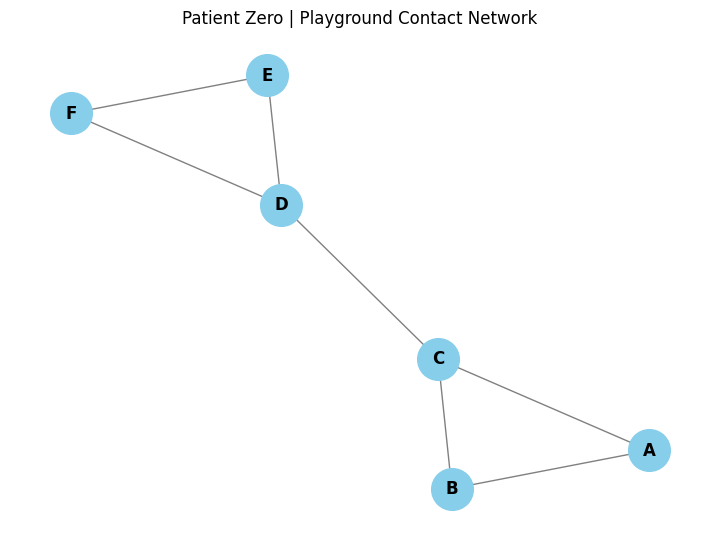

In [30]:

import networkx as nx
import matplotlib.pyplot as plt

# Create a small undirected contact network
G = nx.Graph()

G.add_nodes_from(["A", "B", "C", "D", "E", "F"])

G.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "C"),
    ("C", "D"),
    ("D", "E"),
    ("D", "F"),
    ("E", "F")
])

# Inspect the network structure
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Degrees:", dict(G.degree()))
print("Neighbours of C:", list(G.neighbors("C")))

# Calculate network metrics
print("\nAverage degree:", sum(dict(G.degree()).values()) / G.number_of_nodes())
print("Average clustering:", nx.average_clustering(G))
print("Connected components:", nx.number_connected_components(G))
print("Average shortest path:", nx.average_shortest_path_length(G))

# Visualize the network
plt.figure(figsize=(7, 5))

nx.draw(
    G,
    pos=nx.spring_layout(G, seed=42),
    with_labels=True,
    node_color="skyblue",
    node_size=900,
    edge_color="gray",
    font_weight="bold"
)

plt.title("Patient Zero | Playground Contact Network")
plt.show()


In [31]:
G.remove_edge("C", "D")

print("Connected components:", nx.number_connected_components(G))
print("Component members:", list(nx.connected_components(G)))

Connected components: 2
Component members: [{'A', 'B', 'C'}, {'D', 'E', 'F'}]


Stochastic SIR

In [32]:

import numpy as np

# Hypothetical disease parameters
beta = 0.3
gamma = 0.1
target_avg_degree = 8
infected_neighbours = 3
dt = 1

# Convert continuous-time rates into daily probabilities
p_infection = 1 - np.exp(
    -beta * infected_neighbours * dt / target_avg_degree
)
p_recovery = 1 - np.exp(-gamma * dt)

print(f"Daily infection probability: {p_infection:.2%}")
print(f"Daily recovery probability: {p_recovery:.2%}")

# Simulate 10,000 independent infection and recovery trials
rng = np.random.default_rng(42)
trials = 10_000

infection_events = rng.random(trials) < p_infection
recovery_events = rng.random(trials) < p_recovery

print(f"\nObserved infection frequency: {infection_events.mean():.2%}")
print(f"Observed recovery frequency: {recovery_events.mean():.2%}")


Daily infection probability: 10.64%
Daily recovery probability: 9.52%

Observed infection frequency: 10.49%
Observed recovery frequency: 9.14%


In [33]:

print(infection_events[:10])
print(recovery_events[:10])


[False False False False  True False False False False False]
[False False False  True False False False False False False]


In [34]:

# Generate random values and preserve them
random_values = rng.random(10)

# Convert the random values into infection outcomes
infection_outcomes = random_values < p_infection

for value, outcome in zip(random_values, infection_outcomes):
    print(f"Random draw: {value:.4f} | Infected: {outcome}")


Random draw: 0.7408 | Infected: False
Random draw: 0.9958 | Infected: False
Random draw: 0.0410 | Infected: True
Random draw: 0.2449 | Infected: False
Random draw: 0.5977 | Infected: False
Random draw: 0.4152 | Infected: False
Random draw: 0.6376 | Infected: False
Random draw: 0.5864 | Infected: False
Random draw: 0.7880 | Infected: False
Random draw: 0.0709 | Infected: True


Comparing Random and Degree-Targeted Vaccination

scale-free network with 30 people, vaccinate 20%

In [35]:

import networkx as nx
import numpy as np

# Create a small scale-free network
graph = nx.barabasi_albert_graph(n=500, m=2, seed=42)

# Vaccinate 20% of the population
coverage = 0.20
n_vaccinated = round(graph.number_of_nodes() * coverage)

# Strategy A: Random vaccination
rng = np.random.default_rng(42)
random_vaccinated = set(
    rng.choice(list(graph.nodes()), size=n_vaccinated, replace=False)
)

# Strategy B: Degree-targeted vaccination
degree_ranking = sorted(
    graph.degree(),
    key=lambda item: item[1],
    reverse=True
)

targeted_vaccinated = {
    node for node, degree in degree_ranking[:n_vaccinated]
}

# Compare selected nodes and their degrees
print("Random vaccination:")
print(sorted((node, graph.degree(node)) for node in random_vaccinated))

print("\nDegree-targeted vaccination:")
print(sorted((node, graph.degree(node)) for node in targeted_vaccinated))

print("\nAverage degree of vaccinated nodes:")
print("Random:", np.mean([graph.degree(n) for n in random_vaccinated]))
print("Targeted:", np.mean([graph.degree(n) for n in targeted_vaccinated]))


Random vaccination:
[(np.int64(19), 7), (np.int64(27), 17), (np.int64(30), 4), (np.int64(34), 5), (np.int64(35), 9), (np.int64(38), 3), (np.int64(39), 8), (np.int64(47), 5), (np.int64(53), 4), (np.int64(61), 9), (np.int64(69), 14), (np.int64(70), 4), (np.int64(72), 9), (np.int64(77), 6), (np.int64(82), 9), (np.int64(87), 7), (np.int64(89), 3), (np.int64(98), 2), (np.int64(108), 2), (np.int64(119), 4), (np.int64(121), 3), (np.int64(143), 6), (np.int64(151), 3), (np.int64(152), 4), (np.int64(156), 4), (np.int64(157), 4), (np.int64(164), 2), (np.int64(169), 3), (np.int64(171), 3), (np.int64(173), 7), (np.int64(175), 3), (np.int64(177), 4), (np.int64(189), 2), (np.int64(190), 6), (np.int64(191), 4), (np.int64(194), 2), (np.int64(199), 3), (np.int64(210), 3), (np.int64(211), 2), (np.int64(213), 2), (np.int64(214), 3), (np.int64(216), 4), (np.int64(218), 2), (np.int64(220), 2), (np.int64(226), 4), (np.int64(233), 2), (np.int64(240), 4), (np.int64(249), 4), (np.int64(263), 3), (np.int64(270),

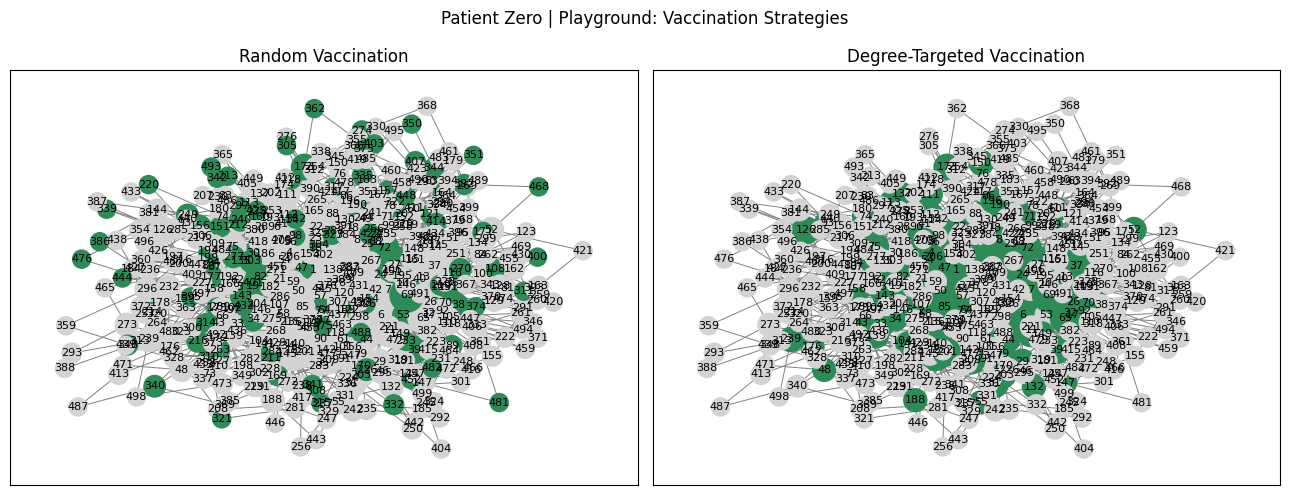

In [36]:

import matplotlib.pyplot as plt

# Use identical node positions for a fair visual comparison
positions = nx.spring_layout(graph, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

strategies = {
    "Random Vaccination": random_vaccinated,
    "Degree-Targeted Vaccination": targeted_vaccinated
}

for ax, (strategy, vaccinated) in zip(axes, strategies.items()):
    node_colors = [
        "seagreen" if node in vaccinated else "lightgray"
        for node in graph.nodes()
    ]

    node_sizes = [
        100 + graph.degree(node) * 35
        for node in graph.nodes()
    ]

    nx.draw_networkx(
        graph,
        pos=positions,
        ax=ax,
        node_color=node_colors,
        node_size=node_sizes,
        edge_color="gray",
        width=0.7,
        with_labels=True,
        font_size=8
    )

    ax.set_title(strategy)

fig.suptitle("Patient Zero | Playground: Vaccination Strategies")
plt.tight_layout()
plt.show()


In [37]:
#disease state encoding
SUSCEPTIBLE=0
INFECTED=1
RECOVERED=2

def initialize_states(graph,initial_infected_pct,rng):
    """Assign initial disease states to network individuals"""
    population=graph.number_of_nodes()
    initial_infected_count=int(population*initial_infected_pct)
    
    #an array with 500 zeros (placeholders / initial values) for 500 susceptible individuals
    #np.int8 is for saving memory since we only need 0, 1, and 2
    states=np.full(population,SUSCEPTIBLE,dtype=np.int8)
    
    infected_nodes=rng.choice(population,size=initial_infected_count,replace=False)
    states[infected_nodes]=INFECTED
    
    return states
    

In [38]:
def stochastic_sir_step(graph,states,beta,gamma,rng,dt=1):
    """Advance the network-based SIR model by one time step"""
    #next day states for every individual
    #this is to maintain synchronous updates
    next_states=states.copy() 
    
    for node in graph.nodes():
        if states[node]==SUSCEPTIBLE:
            infected_neighbors=sum(states[neighbor]==INFECTED for neighbor in graph.neighbors(node))
            infection_prob=1-np.exp(-beta*infected_neighbors*dt/target_avg_degree)
            
            if rng.random()<infection_prob:
                next_states[node]=INFECTED
    recovery_prob=1-np.exp(-gamma*dt)
    for node in graph.nodes():
        if states[node]==INFECTED:
            if rng.random()<recovery_prob:
                next_states[node]=RECOVERED
    return next_states

In [39]:
#full outbreak simulation
def run_stochastic_sir(graph,initial_infected_pct,beta,gamma,max_days=1000,seed=42):
    """Simulate a stochastic SIR outbreak in a contact network"""
    rng=np.random.default_rng(seed)
    states=initialize_states(graph,initial_infected_pct,rng)
    history=[]
    
    for day in range(max_days+1):
        history.append({
            "day": day,
            "susceptible": np.sum(states==SUSCEPTIBLE),
            "infected": np.sum(states==INFECTED),
            "recovered": np.sum(states==RECOVERED)
        })
        
        if np.sum(states==INFECTED)==0:
            break
        
        if day==max_days:
            break
        
        states=stochastic_sir_step(graph,states,beta,gamma,rng)
    return pd.DataFrame(history)

In [40]:

import pandas as pd

# Compare outbreaks using the same original network
vaccination_scenarios = {
    "No Vaccination": set(),
    "Random Vaccination": random_vaccinated,
    "Degree-Targeted Vaccination": targeted_vaccinated
}

outbreak_results = {}

for strategy, vaccinated_nodes in vaccination_scenarios.items():

    # Remove vaccinated individuals from possible transmission paths
    active_graph = graph.copy()
    active_graph.remove_nodes_from(vaccinated_nodes)

    # Relabel remaining nodes from 0 to N-1 for NumPy indexing
    active_graph = nx.convert_node_labels_to_integers(
        active_graph,
        ordering="sorted"
)

    # Use one initial infected individual for each scenario
    initial_pct = 25 / active_graph.number_of_nodes()

    result = run_stochastic_sir(
        graph=active_graph,
        initial_infected_pct=initial_pct,
        beta=0.3,
        gamma=0.1,
        max_days=200,
        seed=42
    )

    outbreak_results[strategy] = result

    # The simulator's recovered count excludes vaccinated individuals
    peak_infected = result["infected"].max()
    final_infected = result["recovered"].iloc[-1]
    duration = result["day"].iloc[-1]

    print(f"\n{strategy}")
    print(f"Peak infected: {peak_infected}")
    print(f"Final outbreak size: {final_infected}")
    print(f"Outbreak duration: {duration} days")
    print(f"Attack rate: {final_infected / graph.number_of_nodes():.1%}")



No Vaccination
Peak infected: 82
Final outbreak size: 247
Outbreak duration: 76 days
Attack rate: 49.4%

Random Vaccination
Peak infected: 50
Final outbreak size: 169
Outbreak duration: 88 days
Attack rate: 33.8%

Degree-Targeted Vaccination
Peak infected: 25
Final outbreak size: 29
Outbreak duration: 92 days
Attack rate: 5.8%


In [41]:
for strategy, result in outbreak_results.items():
    print(f"\n{strategy}")
    print("Day 0 infected:", result["infected"].iloc[0])
    print("Day 0 susceptible:", result["susceptible"].iloc[0])
    print("Day 0 recovered:", result["recovered"].iloc[0])
    print("Final infected:", result["infected"].iloc[-1])
    print("Final recovered:", result["recovered"].iloc[-1])


No Vaccination
Day 0 infected: 25
Day 0 susceptible: 475
Day 0 recovered: 0
Final infected: 0
Final recovered: 247

Random Vaccination
Day 0 infected: 25
Day 0 susceptible: 375
Day 0 recovered: 0
Final infected: 0
Final recovered: 169

Degree-Targeted Vaccination
Day 0 infected: 25
Day 0 susceptible: 375
Day 0 recovered: 0
Final infected: 0
Final recovered: 29


In [42]:

# Repeat each vaccination scenario across 10 random seeds
monte_carlo_results = []

for strategy, vaccinated_nodes in vaccination_scenarios.items():
    active_graph = graph.copy()
    active_graph.remove_nodes_from(vaccinated_nodes)
    active_graph = nx.convert_node_labels_to_integers(
        active_graph, ordering="sorted"
    )

    for seed in range(10):
        result = run_stochastic_sir(
            graph=active_graph,
            initial_infected_pct=25 / active_graph.number_of_nodes(),
            beta=0.3,
            gamma=0.1,
            max_days=200,
            seed=seed
        )

        monte_carlo_results.append({
            "strategy": strategy,
            "seed": seed,
            "peak_infected": result["infected"].max(),
            "final_outbreak_size": result["recovered"].iloc[-1],
            "duration": result["day"].iloc[-1]
        })

monte_carlo_df = pd.DataFrame(monte_carlo_results)

# Compare average outcomes across strategies
summary = monte_carlo_df.groupby("strategy")[
    ["peak_infected", "final_outbreak_size", "duration"]
].agg(["mean", "std"])

print(summary.round(2))


                            peak_infected        final_outbreak_size         \
                                     mean    std                mean    std   
strategy                                                                      
Degree-Targeted Vaccination          25.1   0.32                34.7   2.75   
No Vaccination                       61.5  14.86               209.3  29.48   
Random Vaccination                   52.4   8.50               158.9  27.17   

                            duration         
                                mean    std  
strategy                                     
Degree-Targeted Vaccination     49.8  18.23  
No Vaccination                  98.9  18.71  
Random Vaccination              81.3  17.16  


In [43]:
SUSCEPTIBLE=0
INFECTED=1
RECOVERED=2
VACCINATED=3

In [44]:
def initialize_sirv_states(graph,initial_infected_pct,vacc_nodes,rng):
    population=graph.number_of_nodes()
    initial_infected_count=round(population*initial_infected_pct)
    
    if not 0<=initial_infected_pct<=1:
        raise ValueError("Initial infected percentage must be between 0 and 1")
    if not vacc_nodes.issubset(set(graph.nodes())):
        raise ValueError("Vaccinated nodes must exist in the graph")
    
    eligible_nodes=[node for node in graph.nodes() if node not in vacc_nodes]
    
    if initial_infected_count>len(eligible_nodes):
        raise ValueError("Not enough unvaccinated nodes to initialize infections")
    
    states=np.full(population,SUSCEPTIBLE,dtype=int)
    
    for node in vacc_nodes:
        states[node]=VACCINATED
    
    if initial_infected_count>0:
        infected_nodes=rng.choice(eligible_nodes,size=initial_infected_count,replace=False)
        
        for node in infected_nodes:
            states[node]=INFECTED
    
    return states

In [45]:
#integrating V into the stochastic SIR model -> SIRV model
def run_stochastic_sirv(graph,initial_infected_pct,beta,gamma,vacc_strategy="None",vacc_coverage=0.0,max_days=1000,seed=42):
    rng=np.random.default_rng(seed)
    
    if vacc_strategy=="None":
        if vacc_coverage!=0:
            raise ValueError("No vaccination strategy requires zero coverage")
        vacc_nodes=set()
    elif vacc_strategy=="Random":
        vacc_nodes=select_random_vacc(graph,vacc_coverage,rng)
    elif vacc_strategy=="Degree-Targeted":
        vacc_nodes=select_targeted_vacc(graph,vacc_coverage)
    else:
        raise ValueError("Unknown vaccination strategy")
    
    states=initialize_sirv_states(graph,initial_infected_pct,vacc_nodes,rng)
    history=[]
    
    for day in range(max_days+1):
        history.append({
            "day":day,
            "susceptible":int(np.sum(states==SUSCEPTIBLE)),
            "infected":int(np.sum(states==INFECTED)),
            "recovered":int(np.sum(states==RECOVERED)),
            "vaccinated":int(np.sum(states==VACCINATED)),
        })
        
        if history[-1]["infected"]==0:
            break
        if day==max_days:
            break
        states=stochastic_sir_step(graph,states,beta,gamma,rng)
    return pd.DataFrame(history)

In [46]:
#shared network configuration
network_population=500
target_avg_degree=8
network_seed=42

#topology-specific parameters
random_edge_prob=target_avg_degree/(network_population-1)
small_world_rewiring=0.1
scale_free_attachment=target_avg_degree//2

In [47]:
import networkx as nx
import numpy as np

scale_free=nx.barabasi_albert_graph(network_population,scale_free_attachment,seed=network_seed)

In [48]:
def select_random_vacc(graph,coverage,rng):
    if not 0<=coverage<=1:
        raise ValueError("Vaccination coverage must be between 0 and 1")
    
    population=graph.number_of_nodes()
    vacc_count=round(population*coverage)
    
    if vacc_count==0:
        return set()
    
    vacc_nodes=rng.choice(list(graph.nodes()),size=vacc_count,replace=False)
    
    return set(vacc_nodes)

In [49]:
def select_targeted_vacc(graph,coverage):
    if not 0<=coverage<=1:
        raise ValueError("Vaccination coverage must be between 0 and 1")
    
    population=graph.number_of_nodes()
    vacc_count=round(population*coverage)
    
    if vacc_count==0:
        return set()
    
    degree_ranking=sorted(graph.degree(),key=lambda item:(-item[1],item[0]))
    vacc_nodes={node for node,degree in degree_ranking[:vacc_count]}
    
    return vacc_nodes

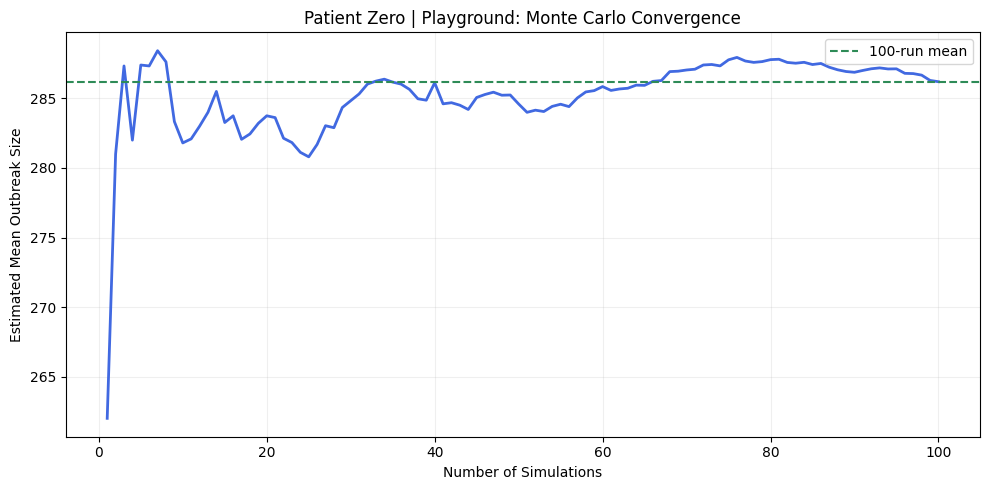

5 runs: mean = 287.40
10 runs: mean = 281.80
30 runs: mean = 284.83
100 runs: mean = 286.20


In [50]:

# Monte Carlo convergence experiment
outbreak_sizes = []

for seed in range(100):
    result = run_stochastic_sirv(
        graph=scale_free,
        initial_infected_pct=0.05,
        beta=0.3,
        gamma=0.1,
        vacc_strategy="Random",
        vacc_coverage=0.20,
        seed=seed
    )

    outbreak_sizes.append(
        result["recovered"].iloc[-1]
        + result["infected"].iloc[-1]
    )

# Running estimate of the mean outbreak size
running_mean = np.cumsum(outbreak_sizes) / np.arange(1, 101)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    range(1, 101),
    running_mean,
    color="royalblue",
    linewidth=2
)

ax.axhline(
    np.mean(outbreak_sizes),
    color="seagreen",
    linestyle="--",
    label="100-run mean"
)

ax.set_xlabel("Number of Simulations")
ax.set_ylabel("Estimated Mean Outbreak Size")
ax.set_title("Patient Zero | Playground: Monte Carlo Convergence")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

for n in [5, 10, 30, 100]:
    print(f"{n} runs: mean = {np.mean(outbreak_sizes[:n]):.2f}")


In [55]:
rng = np.random.default_rng(42)
print(rng.random())

0.7739560485559633


In [51]:
for seed in range(5):
    rng = np.random.default_rng(seed)
    print(seed, rng.random())

0 0.6369616873214543
1 0.5118216247002567
2 0.2616121342493164
3 0.08564916714362436
4 0.9430561055723676


In [58]:

# Demonstrate how random-number consumption changes later outcomes

rng_a = np.random.default_rng(42)
rng_b = np.random.default_rng(42)

# Simulation A consumes random numbers for vaccination selection
vaccination_draws = rng_a.random(5)

# Both simulations now generate infection-related draws
infection_draws_a = rng_a.random(5)
infection_draws_b = rng_b.random(5)

print("Simulation A:", infection_draws_a)
print("Simulation B:", infection_draws_b)
print("Identical?", np.array_equal(infection_draws_a, infection_draws_b))


Simulation A: [0.97562235 0.7611397  0.78606431 0.12811363 0.45038594]
Simulation B: [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735]
Identical? False


In [59]:

# Create independent random streams
seed_sequence = np.random.SeedSequence(42)

vacc_seed, init_seed, disease_seed = seed_sequence.spawn(3)

vacc_rng = np.random.default_rng(vacc_seed)
init_rng = np.random.default_rng(init_seed)
disease_rng = np.random.default_rng(disease_seed)

# Consume random numbers for vaccination
vaccination_draws = vacc_rng.random(100)

# Generate disease-related random numbers
disease_draws = disease_rng.random(5)

# Recreate the streams using the same master seed
repeat_sequence = np.random.SeedSequence(42)
_, _, repeat_disease_seed = repeat_sequence.spawn(3)

repeat_disease_rng = np.random.default_rng(repeat_disease_seed)
repeat_disease_draws = repeat_disease_rng.random(5)

print("Disease draws:", disease_draws)
print("Repeated draws:", repeat_disease_draws)
print("Identical:", np.array_equal(disease_draws, repeat_disease_draws))


Disease draws: [0.0712392  0.71015972 0.07180046 0.31932759 0.67079902]
Repeated draws: [0.0712392  0.71015972 0.07180046 0.31932759 0.67079902]
Identical: True


In [61]:
networks={
    "Random": nx.erdos_renyi_graph(network_population,random_edge_prob,seed=network_seed),
    "Small-world": nx.watts_strogatz_graph(network_population,target_avg_degree,small_world_rewiring,seed=network_seed),
    "Scale-free": nx.barabasi_albert_graph(network_population,scale_free_attachment,seed=network_seed)
    }

In [63]:

import time

benchmark_results = []

for topology, graph in networks.items():
    start = time.perf_counter()

    for seed in range(30):
        run_stochastic_sirv(
            graph=graph,
            initial_infected_pct=0.05,
            beta=0.3,
            gamma=0.1,
            vacc_strategy="Random",
            vacc_coverage=0.20,
            seed=seed
        )

    elapsed = time.perf_counter() - start

    benchmark_results.append({
        "topology": topology,
        "total_seconds": elapsed,
        "seconds_per_run": elapsed / 30
    })

benchmark_df = pd.DataFrame(benchmark_results)
benchmark_df


,topology,total_seconds,seconds_per_run
0,Random,5.058448,0.168615
1,Small-world,7.811840,0.260395
2,Scale-free,4.126908,0.137564


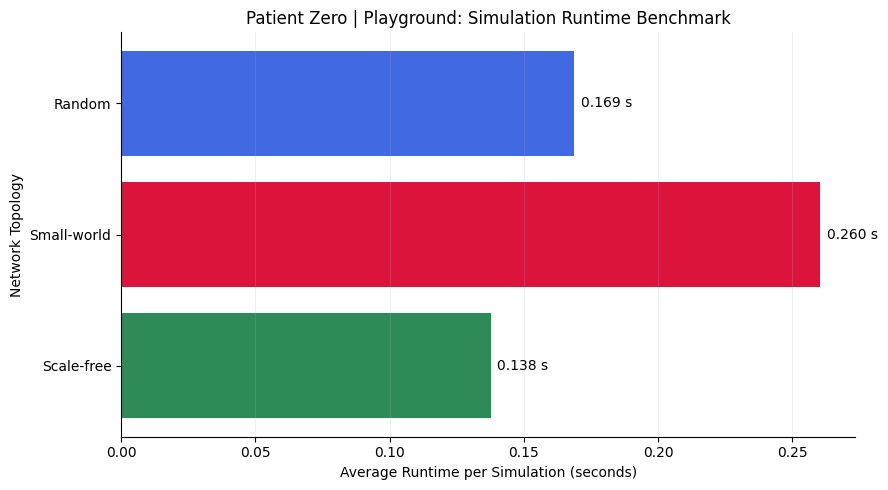

In [66]:

topology_colors = {
    "Random": "royalblue",
    "Small-world": "crimson",
    "Scale-free": "seagreen"
}

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    benchmark_df["topology"],
    benchmark_df["seconds_per_run"],
    color=[
        topology_colors[topology]
        for topology in benchmark_df["topology"]
    ]
)

ax.bar_label(bars, fmt="%.3f s", padding=5)

ax.set_xlabel("Average Runtime per Simulation (seconds)")
ax.set_ylabel("Network Topology")
ax.set_title("Patient Zero | Playground: Simulation Runtime Benchmark")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()
